# 02 · Modeling

Protocol: hyper-parameters and probability thresholds are chosen on **VALIDATION** (fit on
TRAIN), then the chosen configuration is refit on TRAIN+VALIDATION and evaluated once on
**TEST** (2024 → today). Models: hand rules, DecisionTree, RandomForest (lecture) +
XGBoost, LightGBM, LogisticRegression (new) + an RF/XGB/LGBM probability ensemble.


In [1]:
import sys, warnings, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
pd.set_option("display.max_columns", 40); pd.set_option("display.width", 200)
plt.rcParams.update({"figure.figsize": (11, 4.5), "axes.grid": True, "grid.alpha": 0.3})
from driftrev import config, store, artifacts, dataset, features, models, simulate, analysis, pipeline
print("data dir:", config.DATA_DIR)

data dir: /Users/mac/Documents/New project/stock-data-analysis/project/data


In [2]:
events = store.read_table("events"); ml, feats = dataset.prepare(events)
ml.groupby("split")[dataset.TARGET].agg(["size", "mean"])

,size,mean
split,,
purged,880,0.180682
test,43015,0.392292
train,79544,0.358468
validation,25616,0.384916


### Hyper-parameter tuning table (validation)

In [3]:
tuning = pd.read_parquet(config.ARTIFACTS_DIR / "tuning.parquet")
tuning.sort_values(["model", "val_prec_top10"], ascending=[True, False]).groupby("model").head(3)

,model,params,val_auc,val_prec_top10,val_prec_top20,val_base_rate,fit_seconds
14,lgbm,"{""n_estimators"": 300, ""num_leaves"": 15, ""learn...",0.555190,0.459586,0.433340,0.384916,3.3
15,lgbm,"{""n_estimators"": 300, ""num_leaves"": 31, ""learn...",0.552943,0.452167,0.436853,0.384916,4.7
17,lgbm,"{""n_estimators"": 600, ""num_leaves"": 31, ""learn...",0.550548,0.448262,0.436073,0.384916,8.1
20,logreg,"{""C"": 1.0}",0.540698,0.446701,0.437439,0.384916,5.3
18,logreg,"{""C"": 0.01}",0.537967,0.443577,0.428655,0.384916,3.0
19,logreg,"{""C"": 0.1}",0.539922,0.442796,0.433340,0.384916,5.2
9,rf,"{""n_estimators"": 300, ""max_depth"": 12, ""min_sa...",0.554213,0.445920,0.434901,0.384916,25.9
7,rf,"{""n_estimators"": 300, ""max_depth"": 8, ""min_sam...",0.553370,0.442015,0.435097,0.384916,18.2
6,rf,"{""n_estimators"": 300, ""max_depth"": 8, ""min_sam...",0.552814,0.440453,0.435097,0.384916,17.5
3,tree,"{""max_depth"": 6, ""min_samples_leaf"": 50}",0.540244,0.449434,0.428460,0.384916,5.2


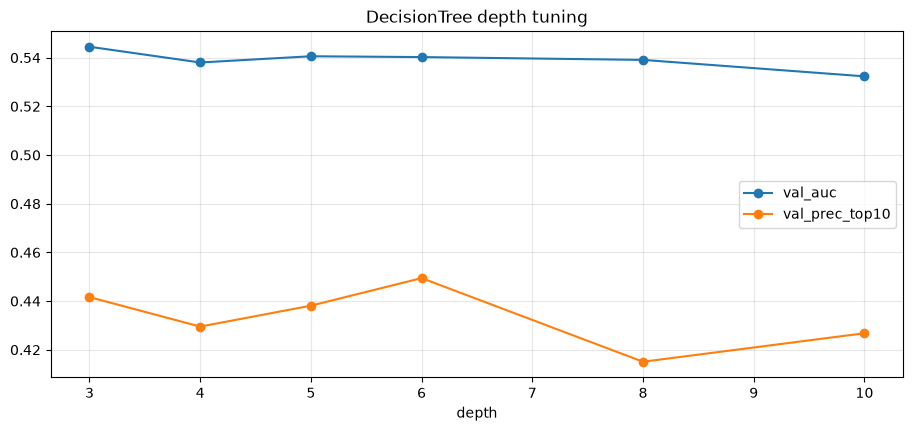

In [4]:
tree = tuning[tuning.model == "tree"].copy(); tree["depth"] = tree.params.map(lambda p: json.loads(p)["max_depth"])
tree.plot(x="depth", y=["val_auc", "val_prec_top10"], marker="o", title="DecisionTree depth tuning"); plt.show()

### Model comparison (validation vs test AUC) and the production choice

In [5]:
metrics = artifacts.load_metrics()
print("production:", metrics["model"]["name"], "| threshold", metrics["model"]["threshold"])
pd.DataFrame(metrics["models"])[["name", "val_auc", "test_auc", "threshold"]].sort_values("val_auc", ascending=False)

production: ensemble | threshold 0.52


,name,val_auc,test_auc,threshold
5,ensemble,0.557201,0.545965,0.52
4,xgb,0.555343,0.544470,0.52
0,lgbm,0.555190,0.543722,0.55
2,rf,0.554213,0.545064,0.51
1,logreg,0.540698,0.548118,0.69
3,tree,0.540244,0.525067,0.53


### Decision rules on TEST (hand rules vs models vs custom rules)

In [6]:
artifacts.load_frame("pred_eval.parquet")

,prediction,n_trades,share,precision,avg_growth_10d,base_rate
0,pred4_logreg_best_rule_69,26,0.000620,0.730769,1.081426,0.392292
1,pred3_lgbm_best_rule_55,160,0.003816,0.543750,1.032790,0.392292
2,pred5_rf_best_rule_51,132,0.003148,0.530303,1.032539,0.392292
3,pred_book_ensemble_rule_52,158,0.003768,0.512658,1.025212,0.392292
4,pred8_ensemble_best_rule_52,190,0.004531,0.505263,1.024232,0.392292
5,pred9_ensemble_top1_daily,128,0.003052,0.500000,1.013910,0.392292
6,pred7_xgb_best_rule_52,282,0.006725,0.468085,1.016224,0.392292
7,pred_manual_dgs10_dgs5,19496,0.464932,0.420702,1.013311,0.392292
8,pred1_manual_panic_no_damage,1587,0.037846,0.420290,1.005462,0.392292
9,pred2_manual_all_events,41933,1.000000,0.392292,1.005052,0.392292


### Feature importance

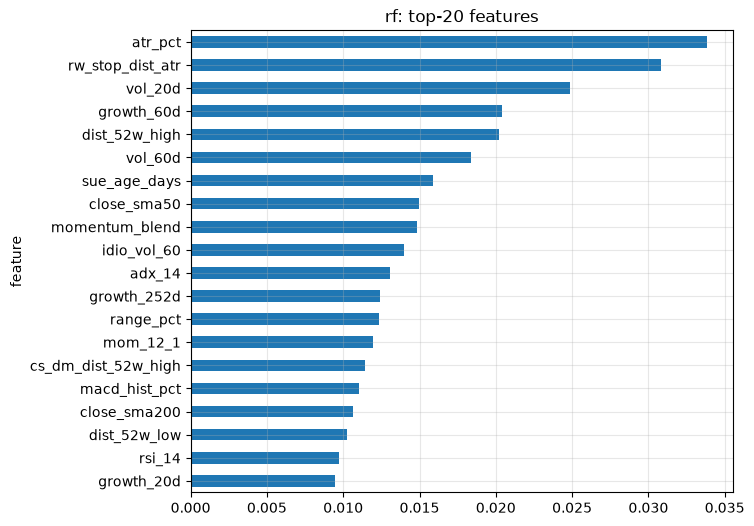

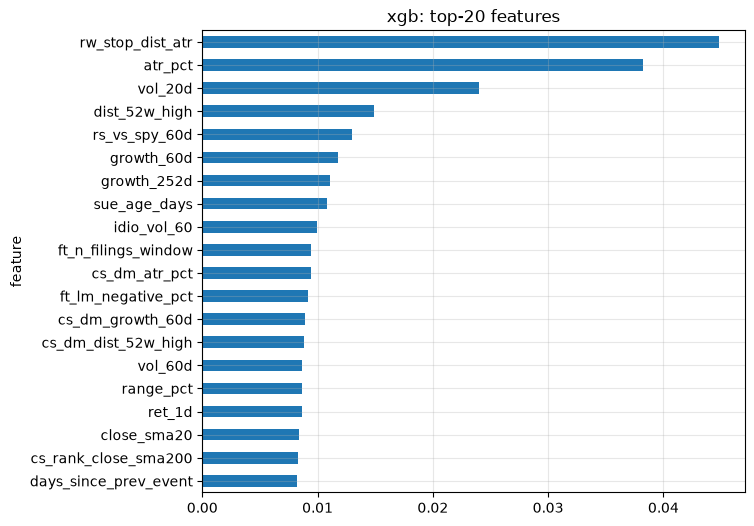

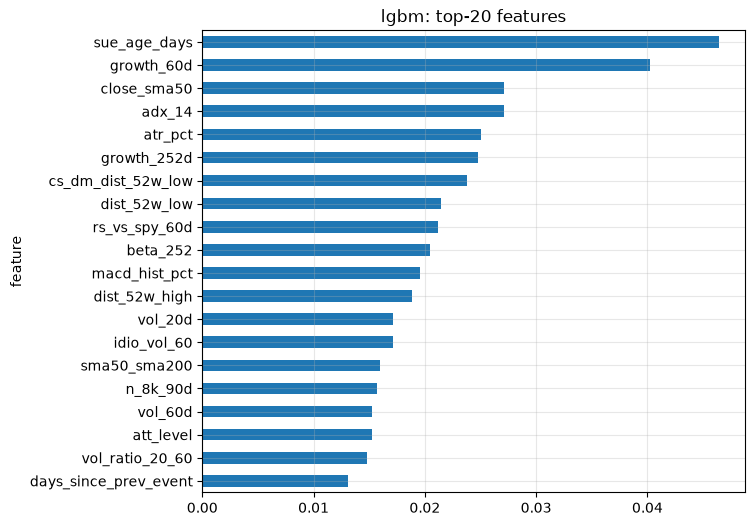

In [7]:
imp = artifacts.load_frame("importance")
for m in ["rf", "xgb", "lgbm"]:
    s = imp[imp.model == m].head(20).set_index("feature")["importance"][::-1]
    s.plot(kind="barh", figsize=(7, 6), title=f"{m}: top-20 features"); plt.show()

### Calibration of the production probabilities on TEST

In [8]:
cal = artifacts.load_frame("calibration.parquet"); cal

,bucket,mean_prob,hit_rate,avg_growth,n
0,"(0.159, 0.299]",0.270414,0.332618,1.004029,4194
1,"(0.299, 0.328]",0.314804,0.359886,1.003210,4193
2,"(0.328, 0.346]",0.337210,0.351777,1.001610,4193
3,"(0.346, 0.359]",0.352605,0.367040,1.002480,4193
4,"(0.359, 0.372]",0.365525,0.388650,1.003484,4194
5,"(0.372, 0.384]",0.377843,0.398760,1.004683,4193
6,"(0.384, 0.398]",0.390868,0.413546,1.006197,4193
7,"(0.398, 0.414]",0.405761,0.413308,1.004845,4193
8,"(0.414, 0.439]",0.426064,0.433580,1.006408,4193
9,"(0.439, 0.622]",0.467827,0.463758,1.013569,4194
